# Scenario - 1 Only Past Power as input


A chronological D to D+1 solar power forecast using only past `Act. Power (MW)`. No weather, calendar, or future time features are used.

# 1. Project Configuration

Imports, paths, artifact locations, and configuration variables are defined in the next cell.

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from pathlib import Path
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.preprocessing import MinMaxScaler
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.layers import (
    Input,
    Masking,
    SimpleRNN,
    Dense,
    Concatenate,
    RepeatVector,
    TimeDistributed,
    Reshape,
)
from tensorflow.keras.models import Model, load_model

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
model_path = artifact_dir / "scenario1_encoder_decoder.keras"
scaler_path = artifact_dir / "scenario1_scaler.joblib"
results_path = artifact_dir / "scenario1_test_results.npz"

W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

# 2. Load Dataset

Load the existing chronological Excel datasets and inspect their row/day counts. No raw data or split files are changed.

In [3]:
def load_data(train_path, validation_path, test_path):
    """Load the three existing chronological Excel splits without re-splitting."""
    train = pd.read_excel(train_path)
    validation = pd.read_excel(validation_path)
    test = pd.read_excel(test_path)

    for split in (train, validation, test):
        split['TimeStamp'] = pd.to_datetime(split['TimeStamp'])
        split['Date'] = split['TimeStamp'].dt.date
        split.sort_values('TimeStamp', inplace=True)
        split.reset_index(drop=True, inplace=True)

    return train, validation, test


W_TRAIN = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Training.xlsx"
W_VALIDATION = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Val.xlsx"
W_TEST = r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Winter\Winter Test.xlsx"

train, validation, test = load_data(W_TRAIN, W_VALIDATION, W_TEST)

print('Train days      :', train['Date'].nunique())
print('Validation days :', validation['Date'].nunique())
print('Test days       :', test['Date'].nunique())
print()
print('Train rows      :', len(train))
print('Validation rows :', len(validation))
print('Test rows       :', len(test))
# February 7 provides input history for the first test forecast.
history_date = pd.Timestamp("2026-02-07").date()
first_test_history = validation.loc[validation["Date"] == history_date]

# Use this dataframe when building test sequences.
test_with_history = pd.concat([first_test_history, test], ignore_index=True)

# Verify every 15-minute timestamp, including the validation/test boundary.
expected_times = pd.date_range("2026-02-07", periods=8 * 96, freq="15min")
actual_times = pd.DatetimeIndex(test_with_history["TimeStamp"])

if len(first_test_history) != 96 or not actual_times.equals(expected_times):
    raise ValueError(
        "Expected 96 validation history blocks on February 7 and "
        "672 consecutive test blocks covering February 8–14, 2026."
    )

print("History day       :", history_date)
print("Forecast dates    :", test["Date"].min(), "to", test["Date"].max())
print("Expected forecasts: 7 days × 4 revisions = 28, each with 96 values")

Train days      : 86
Validation days : 30
Test days       : 7

Train rows      : 8256
Validation rows : 2880
Test rows       : 672
History day       : 2026-02-07
Forecast dates    : 2026-02-08 to 2026-02-14
Expected forecasts: 7 days × 4 revisions = 28, each with 96 values


# 3. Train / Validation / Test Split

The notebook uses the existing chronological Excel splits without re-splitting or shuffling the datasets.

# 4. Revision Sample Creation

Put the existing revision lengths, target length, padded input length, sample creator, and train/validation/test sample creation in this section.

In [4]:
REVISION_LENGTHS = {
    'R0': 32,
    'R1': 50,
    'R2': 64,
    'R3': 82,
}
TARGET_LENGTH = 96
PADDED_INPUT_LENGTH = 82
BLOCKS_PER_DAY = 96
POWER_COLUMN = 'Act. Power (MW)'
def create_revision_samples(split):
    sample_dates = []
    """Create real D -> D+1 samples; padding is added after scaling."""
    day_groups = {
        date: day_data.sort_values('TimeStamp')
        for date, day_data in split.groupby('Date', sort=True)
    }
    X = []
    y = []
    revision_labels = []
    revision_sample_indices = {revision: [] for revision in REVISION_LENGTHS}
    for day, day_data in day_groups.items():
        next_day = (pd.Timestamp(day) + pd.Timedelta(days=1)).date()
        next_day_data = day_groups.get(next_day)
        if next_day_data is None or len(day_data) < PADDED_INPUT_LENGTH:
            continue
        if len(next_day_data) != TARGET_LENGTH:
            continue
        day_power = day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
        next_day_power = next_day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
        for revision, sequence_length in REVISION_LENGTHS.items():
            history = day_power[:sequence_length, np.newaxis]
            sample_index = len(X)
            X.append(history)
            y.append(next_day_power)
            revision_labels.append(revision)
            sample_dates.append(next_day)
            revision_sample_indices[revision].append(sample_index)
    return (
    X,
    np.asarray(y, dtype=np.float32),
    np.asarray(revision_labels),
    revision_sample_indices,
    np.asarray(sample_dates),
)
# Build D → D+1 samples for Scenario 1: past power only.
X_train, y_train, revision_labels_train, revision_indices_train, dates_train = (
    create_revision_samples(train)
)

X_validation, y_validation, revision_labels_validation, revision_indices_validation, dates_validation = (
    create_revision_samples(validation)
)

X_test, y_test, revision_labels_test, revision_indices_test, dates_test = (
    create_revision_samples(test_with_history)
)

revision_info = {
    'lengths': REVISION_LENGTHS,
    'train': revision_indices_train,
    'validation': revision_indices_validation,
    'test': revision_indices_test,
}

# Check all 7 target dates and all 4 revisions before prediction.
expected_dates = pd.date_range('2026-02-08', '2026-02-14', freq='D').date
expected_pairs = {
    (date, revision)
    for date in expected_dates
    for revision in REVISION_LENGTHS
}
actual_pairs = set(zip(dates_test, revision_labels_test))

if actual_pairs != expected_pairs or y_test.shape != (len(expected_pairs), TARGET_LENGTH):
    raise ValueError(
        'Expected one 96-block target for each date and revision '
        'from February 8–14, 2026. Check the test timestamps and input history.'
    )

print('Split       | Samples | Target shape')
for split_name, targets in (
    ('Train', y_train),
    ('Validation', y_validation),
    ('Test', y_test),
):
    print(f'{split_name:<11} | {len(targets):>7} | {targets.shape}')

print('\nTest samples per target date and revision:')
print(pd.crosstab(
    pd.Series(dates_test, name='Target date'),
    pd.Series(revision_labels_test, name='Revision'),
))

Split       | Samples | Target shape
Train       |     340 | (340, 96)
Validation  |     116 | (116, 96)
Test        |      28 | (28, 96)

Test samples per target date and revision:
Revision     R0  R1  R2  R3
Target date                
2026-02-08    1   1   1   1
2026-02-09    1   1   1   1
2026-02-10    1   1   1   1
2026-02-11    1   1   1   1
2026-02-12    1   1   1   1
2026-02-13    1   1   1   1
2026-02-14    1   1   1   1


In [5]:
from sklearn.preprocessing import MinMaxScaler
# Fit only on real training power values from the raw training dataframe.
scaler = MinMaxScaler()
scaler.fit(train[[POWER_COLUMN]].to_numpy())

train_power_scaled = scaler.transform(train[[POWER_COLUMN]].to_numpy())
val_power_scaled = scaler.transform(validation[[POWER_COLUMN]].to_numpy())
test_power_scaled = scaler.transform(test[[POWER_COLUMN]].to_numpy())

# 5. Preprocessing and Scaling

This section preserves the existing `MinMaxScaler`, time features, padding, and scaled input creation.

In [6]:
# Scale real power, add block-time features, then pad all three input channels with -1.
def time_features(block_indices):
    block_indices = np.asarray(block_indices, dtype=np.float32)
    phase = 2.0 * np.pi * block_indices / BLOCKS_PER_DAY
    return np.column_stack((np.sin(phase), np.cos(phase))).astype(np.float32)
def preprocess_revision_samples(X_raw, y_raw, revision_labels, scaler):
    X_processed = np.full(
        (len(X_raw), PADDED_INPUT_LENGTH, 3),
        -1.0,
        dtype=np.float32,
    )
    y_scaled = scaler.transform(y_raw.reshape(-1, 1)).reshape(y_raw.shape).astype(np.float32)

    for revision, real_length in REVISION_LENGTHS.items():
        revision_mask = revision_labels == revision
        real_power = np.asarray(
            [sample[:, 0] for sample, is_revision in zip(X_raw, revision_mask) if is_revision],
            dtype=np.float32,
        )
        scaled_power = scaler.transform(real_power.reshape(-1, 1)).reshape(
            -1, real_length
        )
        temporal_features = time_features(np.arange(real_length))
        X_processed[revision_mask, :real_length, 0] = scaled_power
        X_processed[revision_mask, :real_length, 1:] = temporal_features

    return X_processed, y_scaled
X_train_scaled, y_train_scaled = preprocess_revision_samples(
    X_train, y_train, revision_labels_train, scaler
)
X_validation_scaled, y_validation_scaled = preprocess_revision_samples(
    X_validation, y_validation, revision_labels_validation, scaler
)
X_test_scaled, y_test_scaled = preprocess_revision_samples(
    X_test, y_test, revision_labels_test, scaler
)
for name, X, y, labels, expected_days in (
    ('Train', X_train_scaled, y_train_scaled, revision_labels_train, 85),
    ('Validation', X_validation_scaled, y_validation_scaled, revision_labels_validation, 29),
    ('Test', X_test_scaled, y_test_scaled, revision_labels_test, 7),
):
    expected_samples = expected_days * len(REVISION_LENGTHS)
    assert X.shape == (expected_samples, PADDED_INPUT_LENGTH, 3), f'{name}: input shape'
    assert y.shape == (expected_samples, TARGET_LENGTH), f'{name}: target shape'
    assert np.isfinite(X).all() and np.isfinite(y).all(), f'{name}: missing or infinite values'

    for revision, length in REVISION_LENGTHS.items():
        histories = X[labels == revision]
        assert len(histories) == expected_days, f'{name} {revision}: sample count'
        assert np.all(histories[:, length:, :] == -1.0), f'{name} {revision}: padding'
        assert np.allclose(
            histories[:, :length, 1:],
            time_features(np.arange(length)),
        ), f'{name} {revision}: time features'

    print(f'{name}: {expected_days} target days | X {X.shape} | y {y.shape}')

Train: 85 target days | X (340, 82, 3) | y (340, 96)
Validation: 29 target days | X (116, 82, 3) | y (116, 96)
Test: 7 target days | X (28, 82, 3) | y (28, 96)


# 6. Reproducibility

This section must run before model creation or training.

In [7]:
import os
import random

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)
tf.config.experimental.enable_op_determinism()

print(f"Reproducibility configured with seed {SEED}.")

Reproducibility configured with seed 42.


# 7. Model Architecture

This section contains only the existing encoder-decoder model definition.

In [8]:
import tensorflow as tf
from tensorflow.keras.models import Model
from tensorflow.keras.layers import (
    Input, Masking, SimpleRNN, Dense, Concatenate,
    RepeatVector, TimeDistributed, Reshape,
)
from tensorflow.keras.callbacks import EarlyStopping

# Scenario 1 configuration
SEED = 42
MASK_VALUE = -1.0
N_HISTORY_FEATURES = X_train_scaled.shape[-1]
N_FUTURE_EXOG = 0

assert N_HISTORY_FEATURES == 3, "Scenario 1 expects past power, time sine, and time cosine."


def build_model(n_future_exog):
    """Build the shared RNN architecture for the selected input features."""
    tf.keras.backend.clear_session()
    tf.keras.utils.set_random_seed(SEED)

    encoder_input = Input(
        shape=(PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        name='encoder_input',
    )
    masked_encoder_input = Masking(
        mask_value=MASK_VALUE,
        name='encoder_masking',
    )(encoder_input)
    encoder_context = SimpleRNN(
        64,
        name='encoder_rnn',
    )(masked_encoder_input)

    future_input = Input(
        shape=(TARGET_LENGTH, n_future_exog + 2),
        name='future_input',
    )
    repeated_context = RepeatVector(
        TARGET_LENGTH,
        name='repeat_context',
    )(encoder_context)
    decoder_input = Concatenate(
        axis=-1,
        name='decoder_features',
    )([repeated_context, future_input])

    decoder_sequence = SimpleRNN(
        64,
        return_sequences=True,
        name='decoder_rnn',
    )(decoder_input)
    block_predictions = TimeDistributed(
        Dense(1),
        name='block_prediction',
    )(decoder_sequence)
    forecast = Reshape(
        (TARGET_LENGTH,),
        name='forecast',
    )(block_predictions)

    model = Model(
        inputs=[encoder_input, future_input],
        outputs=forecast,
    )
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae'],
    )

    assert model.input_shape == [
        (None, PADDED_INPUT_LENGTH, N_HISTORY_FEATURES),
        (None, TARGET_LENGTH, n_future_exog + 2),
    ]
    assert model.output_shape == (None, TARGET_LENGTH)

    return model


# Build a fresh Scenario 1 model for training.
model = build_model(N_FUTURE_EXOG)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ encoder_input       │ (None, 82, 3)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ not_equal           │ (None, 82, 3)     │          0 │ encoder_input[0]… │
│ (NotEqual)          │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_masking     │ (None, 82, 3)     │          0 │ encoder_input[0]… │
│ (Masking)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ any (Any)           │ (None, 82)        │          0 │ not_equal[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ encoder_rnn         │ (None, 64)        │      4,352 │ encoder_masking[… │
│ (SimpleRNN)         │                   │            │ any[0][0]         │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ repeat_context      │ (None, 96, 64)    │          0 │ encoder_rnn[0][0] │
│ (RepeatVector)      │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ future_input        │ (None, 96, 2)     │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_features    │ (None, 96, 66)    │          0 │ repeat_context[0… │
│ (Concatenate)       │                   │            │ future_input[0][… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ decoder_rnn         │ (None, 96, 64)    │      8,384 │ decoder_features… │
│ (SimpleRNN)         │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_prediction    │ (None, 96, 1)     │         65 │ decoder_rnn[0][0] │
│ (TimeDistributed)   │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ forecast (Reshape)  │ (None, 96)        │          0 │ block_prediction… │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 12,801 (50.00 KB)

 Trainable params: 12,801 (50.00 KB)

 Non-trainable params: 0 (0.00 B)

# 8. Model Training

**RUN ONLY WHEN TRAINING THE MODEL**  
**DO NOT RUN FOR DEMO**

In [9]:
from pathlib import Path
import joblib
import numpy as np
import pandas as pd
import tensorflow as tf
from tensorflow.keras.callbacks import EarlyStopping

# 1. Create a separate folder for Scenario 1.
notebook_dir = Path(W_TRAIN).parent.parent  # W_TRAIN is in Notebooks/Winter/
artifact_dir = notebook_dir / "Saved_Models" / "Scenario_1"
artifact_dir.mkdir(parents=True, exist_ok=True)

model_path = artifact_dir / "scenario1_encoder_decoder.keras"
preprocessing_path = artifact_dir / "scenario1_preprocessing.joblib"

# 2. Prepare next-day time features for all 96 forecast blocks.
future_time = time_features(np.arange(TARGET_LENGTH))

def make_future_time(n_samples):
    return np.tile(future_time, (n_samples, 1, 1)).astype(np.float32)

future_time_train = make_future_time(len(X_train_scaled))
future_time_validation = make_future_time(len(X_validation_scaled))
future_time_test = make_future_time(len(X_test_scaled))

assert future_time_test.shape == (7 * len(REVISION_LENGTHS), TARGET_LENGTH, 2)

# 3. Load the trained model, or train and save it on the first run.
if model_path.exists():
    saved = joblib.load(preprocessing_path)

    # The previous cell already scaled the inputs. Check that it used
    # the same power transformation as the saved model.
    saved_scaler = saved["scaler"]
    if not (
        np.array_equal(scaler.scale_, saved_scaler.scale_)
        and np.array_equal(scaler.min_, saved_scaler.min_)
    ):
        raise ValueError(
            "The current power scaler differs from the saved scaler. "
            "Load the saved scaler before running the preprocessing cell."
        )

    model = tf.keras.models.load_model(model_path, compile=False)
    scaler = saved_scaler
    night_blocks = saved["night_blocks"]
    print(f"Loaded trained model: {model_path}")

else:
    # Derive the night mask from complete raw training days.
    complete_training_days = []
    for date, day_data in train.groupby("Date", sort=True):
        day_data = day_data.sort_values("TimeStamp")
        expected_times = pd.date_range(date, periods=BLOCKS_PER_DAY, freq="15min")
        if pd.DatetimeIndex(day_data["TimeStamp"]).equals(expected_times):
            complete_training_days.append(
                day_data[POWER_COLUMN].to_numpy(dtype=np.float32)
            )

    if not complete_training_days:
        raise ValueError("No complete 96-block training days found for the night mask.")

    complete_training_power = np.stack(complete_training_days)
    active_fraction = np.mean(complete_training_power > 0.1, axis=0)
    night_blocks = np.flatnonzero(active_fraction < 0.10)

    early_stopping = EarlyStopping(
        monitor="val_loss",
        patience=15,
        restore_best_weights=True,
    )

    # Uses the Scenario 1 model built in the preceding cell.
    history = model.fit(
        [X_train_scaled, future_time_train],
        y_train_scaled,
        validation_data=(
            [X_validation_scaled, future_time_validation],
            y_validation_scaled,
        ),
        epochs=150,
        batch_size=16,
        shuffle=False,
        callbacks=[early_stopping],
        verbose=1,
    )

    # Save the fitted scaler and night mask alongside the trained model.
    joblib.dump(
        {"scaler": scaler, "night_blocks": night_blocks},
        preprocessing_path,
    )
    model.save(model_path)

    print(f"Training completed after {len(history.history['loss'])} epochs.")
    print(f"Model saved to: {model_path}")
    print(f"Preprocessing saved to: {preprocessing_path}")

Epoch 1/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 7s 99ms/step - loss: 0.1453 - mae: 0.2831 - val_loss: 0.0358 - val_mae: 0.1536
Epoch 2/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - loss: 0.0455 - mae: 0.1731 - val_loss: 0.0273 - val_mae: 0.1367
Epoch 3/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 151ms/step - loss: 0.0369 - mae: 0.1608 - val_loss: 0.0255 - val_mae: 0.1321
Epoch 4/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 3s 142ms/step - loss: 0.0314 - mae: 0.1476 - val_loss: 0.0224 - val_mae: 0.1246
Epoch 5/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 14s 641ms/step - loss: 0.0290 - mae: 0.1411 - val_loss: 0.0190 - val_mae: 0.1142
Epoch 6/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 8s 370ms/step - loss: 0.0257 - mae: 0.1303 - val_loss: 0.0154 - val_mae: 0.0995
Epoch 7/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 231ms/step - loss: 0.0227 - mae: 0.1179 - val_loss: 0.0124 - val_mae: 0.0875
Epoch 8/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 4s 170ms/step - loss: 0.0205 - mae: 0.1087 - val_loss: 0.0106 - val_mae: 0.0782
Epoch 9/150
22/22 ━━━━━━━━━━━━━━━━━━━━ 5s 235ms/

# 9. Training Evaluation

Training-only loss visualization. **DO NOT RUN FOR DEMO.**

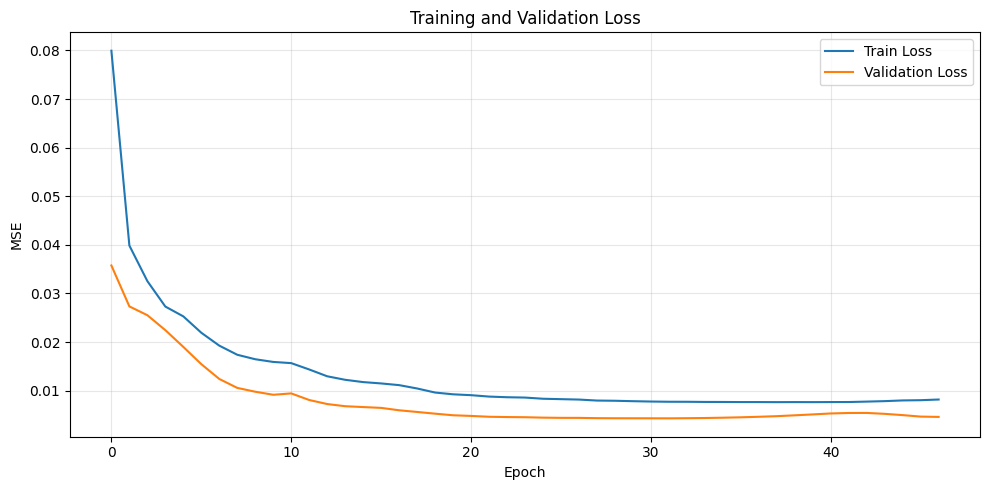

In [10]:
# TRAINING ONLY: requires history from the Model Training section.
plt.figure(figsize=(10, 5))

plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')

plt.xlabel('Epoch')
plt.ylabel('MSE')
plt.title('Training and Validation Loss')

plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

# 10. Test Prediction and Metrics

**RUN ONLY WHEN GENERATING NEW PREDICTIONS**  
This section preserves model prediction, inverse scaling, nighttime constraint, and overall/revision-wise MAE, RMSE, and R².

In [12]:
from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# First results file: daily metrics for one selected test day.
model_name = "RNN"
scenario = "S1"
selected_date = pd.Timestamp("2026-02-08")
target_dates = pd.DatetimeIndex(dates_test).normalize()

rows = []
for revision in ("R0", "R1", "R2", "R3"):
    indices = np.flatnonzero(
        (target_dates == selected_date) & (revision_labels_test == revision)
    )
    if len(indices) != 1:
        raise ValueError(f"Expected one {revision} forecast for {selected_date.date()}.")

    i = indices[0]
    actual = np.asarray(y_test[i], dtype=np.float64)     # Measured power in MW
    forecast = np.asarray(y_pred[i], dtype=np.float64)  # Final forecast in MW

    if actual.shape != (96,) or forecast.shape != (96,):
        raise ValueError(f"{revision}: expected 96 actual and forecast values.")
    if not (np.isfinite(actual).all() and np.isfinite(forecast).all()):
        raise ValueError(f"{revision}: found missing or infinite power values.")

    error = forecast - actual
    generating = actual > 0
    mape = (
        100 * np.mean(np.abs(error[generating] / actual[generating]))
        if generating.any() else np.nan
    )

    rows.append({
        "Model": model_name,
        "Scenario": scenario,
        "Revision": revision.replace("R", "Rev", 1),
        "Date": selected_date.strftime("%d-%b-%Y"),
        "MAE": mean_absolute_error(actual, forecast),
        "RMSE": np.sqrt(mean_squared_error(actual, forecast)),
        "MAPE": mape,
        "R2": r2_score(actual, forecast),
        "MBE": error.mean(),
    })

daily_metrics = pd.DataFrame(rows)

# All four scenario notebooks write to the same results file.
results_dir = Path(W_TRAIN).parent.parent / "Results"
results_dir.mkdir(parents=True, exist_ok=True)
results_path = results_dir / f"Winter_Daily_Metrics_RNN_{selected_date:%Y-%m-%d}.csv"

# Rerunning a scenario updates its four rows and preserves the other scenarios.
if results_path.exists():
    previous = pd.read_csv(results_path)
    if list(previous.columns) != list(daily_metrics.columns):
        raise ValueError(f"Unexpected column layout in {results_path.name}.")
    results = pd.concat([previous, daily_metrics], ignore_index=True)
    results = results.drop_duplicates(
        subset=["Model", "Scenario", "Revision", "Date"], keep="last"
    )
else:
    results = daily_metrics.copy()

results = results.sort_values(["Model", "Scenario", "Revision"], ignore_index=True)
results.to_csv(results_path, index=False)

print(f"Saved to {results_path}")
display(daily_metrics)

Saved to C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Winter_Daily_Metrics_RNN_2026-02-08.csv


,Model,Scenario,Revision,Date,MAE,RMSE,MAPE,R2,MBE
0,RNN,S1,Rev0,08-Feb-2026,0.841337,1.474595,22.889434,0.958927,-0.800705
1,RNN,S1,Rev1,08-Feb-2026,0.820544,1.420450,22.538051,0.961888,-0.749514
2,RNN,S1,Rev2,08-Feb-2026,0.663871,1.166217,17.872869,0.974310,-0.605282
3,RNN,S1,Rev3,08-Feb-2026,0.691654,1.133237,17.152678,0.975742,-0.642867


# 11. Save Test Results

Save `y_actual`, `y_pred`, `revision_labels_test`, and `dates_test` to `scenario1_test_results.npz`. **RUN AFTER NEW PREDICTIONS ONLY.**

In [13]:
from pathlib import Path
import numpy as np
import pandas as pd

scenario = "S1"
prediction_dir = Path(W_TRAIN).parent.parent / "Results" / "Predictions"
prediction_dir.mkdir(parents=True, exist_ok=True)

# Verify that every test day has one 96-block forecast for each revision.
dates = pd.DatetimeIndex(dates_test).normalize()
revision_names = {"R0": "Rev0", "R1": "Rev1", "R2": "Rev2", "R3": "Rev3"}
test_days = pd.date_range("2026-02-08", "2026-02-14", freq="D")

expected = pd.MultiIndex.from_product([test_days, list(revision_names)])
observed = pd.MultiIndex.from_arrays([dates, revision_labels_test])

if not observed.sort_values().equals(expected.sort_values()):
    raise ValueError("Expected all four revisions for each date from February 8–14.")

if y_actual.shape != (28, 96) or y_pred.shape != (28, 96):
    raise ValueError("Expected actual and predicted power arrays of shape (28, 96).")

if not (np.isfinite(y_actual).all() and np.isfinite(y_pred).all()):
    raise ValueError("Actual or predicted power contains missing or infinite values.")

# Each sample becomes 96 rows, from 00:00 through 23:45 IST.
block_offsets = pd.to_timedelta(15 * np.arange(96), unit="min")
predictions = pd.DataFrame({
    "Revision": np.repeat([revision_names[r] for r in revision_labels_test], 96),
    "Target_Time": dates.repeat(96) + np.tile(block_offsets.to_numpy(), len(dates)),
    "Actual_MW": y_actual.ravel(),
    "Forecast_MW": y_pred.ravel(),
}).sort_values(["Revision", "Target_Time"], ignore_index=True)

results_path = prediction_dir / f"Winter_Daily_RNN_{scenario}.csv"
predictions.to_csv(results_path, index=False, date_format="%Y-%m-%d %H:%M")

print(f"Saved {len(predictions):,} prediction rows to {results_path}")

Saved 2,688 prediction rows to C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks\Results\Predictions\Winter_Daily_RNN_S1.csv


# 12. Results / Demonstration

**DEMO / RESULTS ONLY**  
This section loads the saved `.npz` file and generates presentation plots without loading the model or calling `model.fit()`. It is safe to run after restarting the kernel.

In [6]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import r2_score

artifact_dir = Path(r"C:\Users\yashs\Desktop\ML\Project Fall 2026\Notebooks")
results_path = artifact_dir / "scenario1_test_results.npz"
TARGET_LENGTH = 96

results = np.load(results_path, allow_pickle=True)
y_actual = results["y_actual"]
y_pred = results["y_pred"]
revision_labels_test = results["revision_labels"]
dates_test = results["dates_test"]
revision_indices_test = {
    revision: np.flatnonzero(revision_labels_test == revision)
    for revision in ("R0", "R1", "R2", "R3")
}

print(results.files)
print("Actual:", y_actual.shape)
print("Predicted:", y_pred.shape)
print("Revisions:", revision_labels_test.shape)
print("Dates:", dates_test.shape)
print("Unique dates:", np.unique(dates_test))

['y_actual', 'y_pred', 'revision_labels', 'dates_test']
Actual: (24, 96)
Predicted: (24, 96)
Revisions: (24,)
Dates: (24,)
Unique dates: ['2026-02-09' '2026-02-10' '2026-02-11' '2026-02-12' '2026-02-13'
 '2026-02-14']


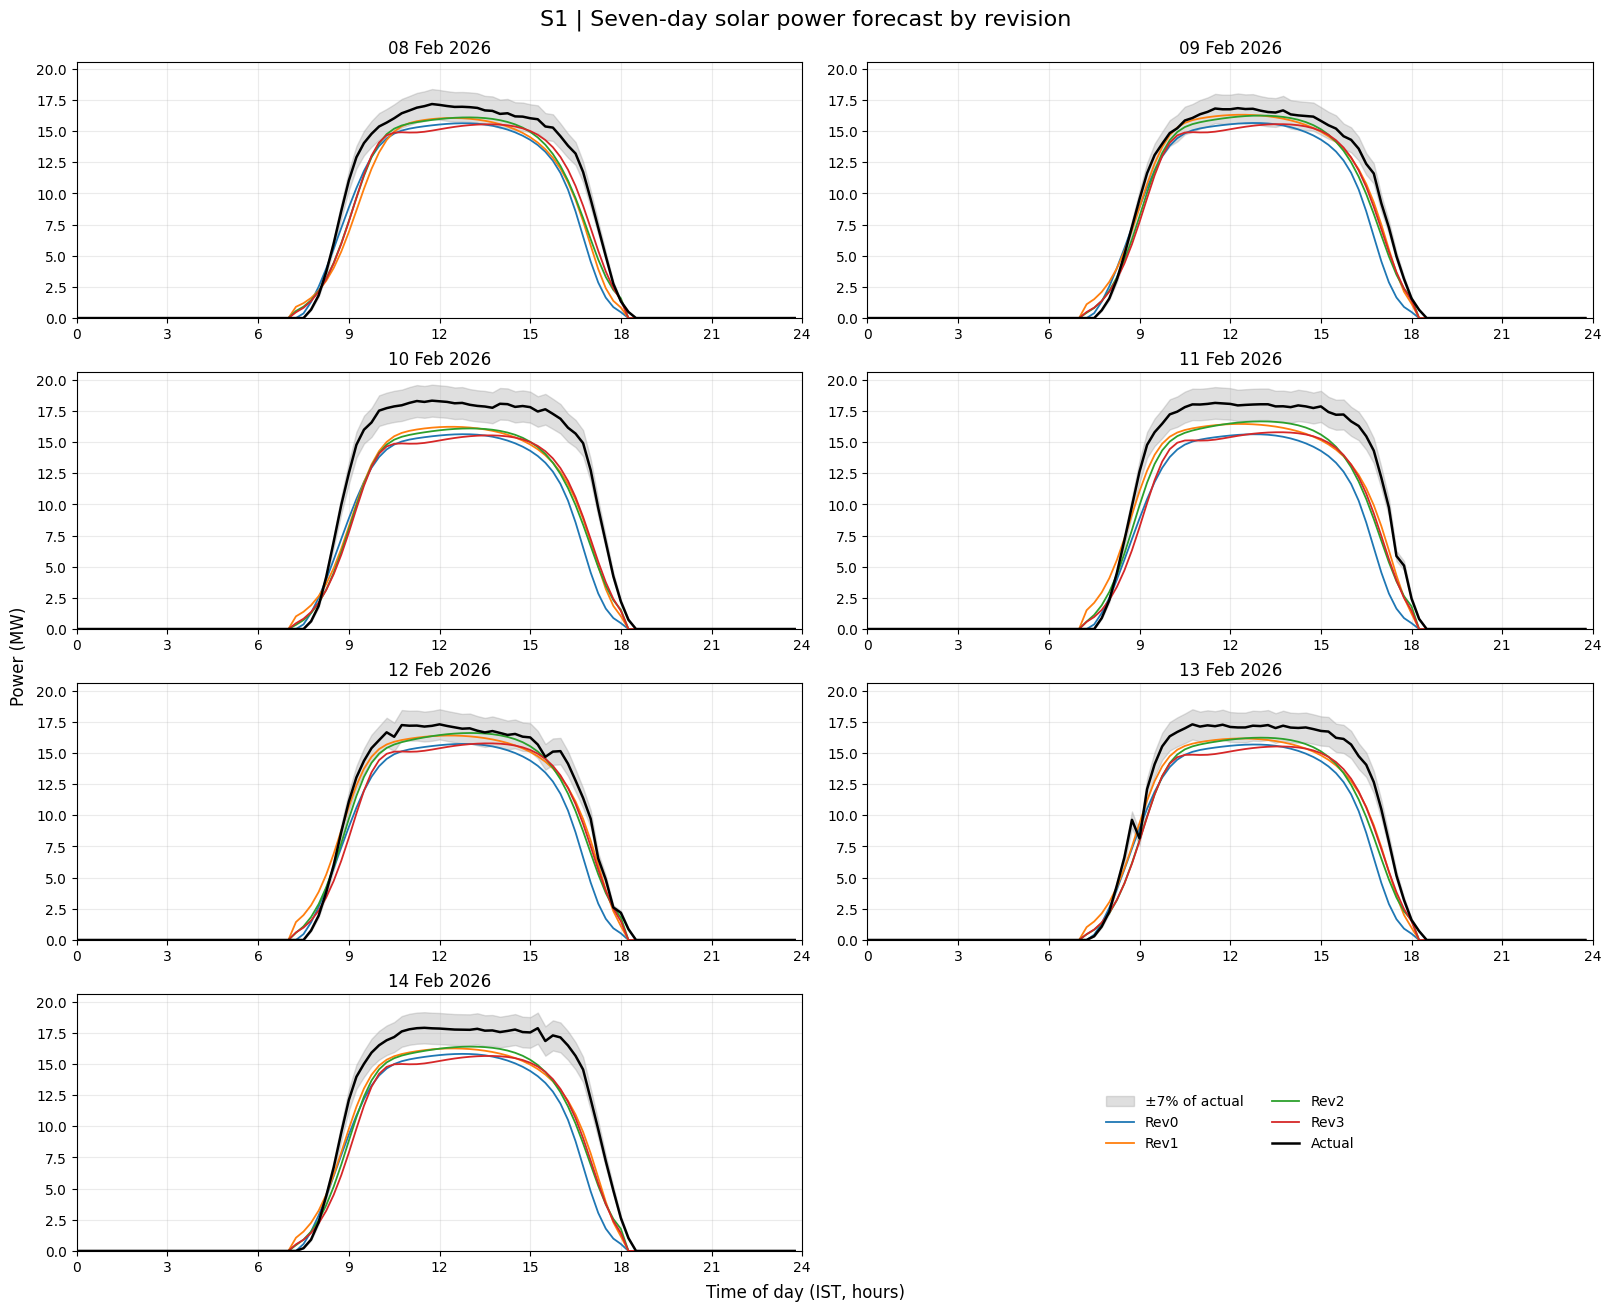

In [15]:
# 7-DAY SOLAR POWER FORECAST BY REVISION
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MultipleLocator

# results_path is the scenario CSV written by the preceding export cell.
predictions = pd.read_csv(results_path, parse_dates=["Target_Time"])
test_days = pd.date_range("2026-02-08", "2026-02-14", freq="D")

revision_colors = {
    "Rev0": "tab:blue",
    "Rev1": "tab:orange",
    "Rev2": "tab:green",
    "Rev3": "tab:red",
}

# One row per timestamp, one forecast column per revision.
forecasts = predictions.pivot(
    index="Target_Time", columns="Revision", values="Forecast_MW"
)
actual = predictions.groupby("Target_Time")["Actual_MW"].first()

expected_times = pd.date_range(test_days[0], periods=7 * 96, freq="15min")
forecasts = forecasts.reindex(index=expected_times, columns=list(revision_colors))
actual = actual.reindex(expected_times)

if forecasts.isna().any().any() or actual.isna().any():
    raise ValueError("Expected actual power and all four forecasts at every 15-minute block.")

fig, axes = plt.subplots(4, 2, figsize=(16, 13), layout="constrained")
hours = np.arange(96) / 4

for ax, day in zip(axes.flat, test_days):
    day_times = pd.date_range(day, periods=96, freq="15min")
    measured = actual.loc[day_times].to_numpy()
    tolerance = 0.07 * np.abs(measured)

    ax.fill_between(
        hours, measured - tolerance, measured + tolerance,
        color="gray", alpha=0.25, label="±7% of actual",
    )
    for revision, color in revision_colors.items():
        ax.plot(
            hours, forecasts.loc[day_times, revision],
            color=color, linewidth=1.3, label=revision,
        )
    ax.plot(hours, measured, color="black", linewidth=1.8, label="Actual")

    ax.set_title(day.strftime("%d %b %Y"))
    ax.set_xlim(0, 24)
    ax.set_xticks(np.arange(0, 25, 3))
    ax.yaxis.set_major_locator(MultipleLocator(2.5))
    ax.grid(alpha=0.25)

# Use the same power scale on all seven days for visual comparison.
upper_limit = max(ax.get_ylim()[1] for ax in list(axes.flat)[:7])
for ax in list(axes.flat)[:7]:
    ax.set_ylim(0, upper_limit)

legend_ax = axes[3, 1]
legend_ax.axis("off")
handles, labels = axes[0, 0].get_legend_handles_labels()
legend_ax.legend(handles, labels, loc="center", ncol=2, frameon=False)

fig.suptitle(f"{scenario} | Seven-day solar power forecast by revision", fontsize=16)
fig.supxlabel("Time of day (IST, hours)")
fig.supylabel("Power (MW)")
plt.show()

DSM BAND CALCULATION

DSM band calculated.


# 13. Optional / Experimental Cells

These cells are exploratory demonstrations or duplicate result checks. **DO NOT EXECUTE AUTOMATICALLY.**

In [12]:
import numpy as np
import pandas as pd

# Change to "Scenario 1" in the old notebook.
SCENARIO_NAME = "Scenario 1"

BAND_FRACTION = 0.07
ACTIVE_THRESHOLD_MW = 0.1
NUMERICAL_TOLERANCE_MW = 1e-6

actual = np.asarray(y_actual, dtype=np.float64)
predicted = np.asarray(y_pred, dtype=np.float64)

assert actual.shape == predicted.shape
assert actual.ndim == 2 and actual.shape[1] == TARGET_LENGTH
assert np.isfinite(actual).all()
assert np.isfinite(predicted).all()

# Absolute width keeps bounds ordered even for negative measured values.
band_width = BAND_FRACTION * np.abs(actual)
lower_bound = actual - band_width
upper_bound = actual + band_width

inside_band = (
    (predicted >= lower_bound - NUMERICAL_TOLERANCE_MW)
    & (predicted <= upper_bound + NUMERICAL_TOLERANCE_MW)
)

rows = []

groups = {
    "Overall": np.arange(len(actual)),
    **{
        revision: np.asarray(indices, dtype=int)
        for revision, indices in revision_indices_test.items()
    },
}

for revision, indices in groups.items():
    if len(indices) == 0:
        continue

    group_actual = actual[indices]
    group_inside = inside_band[indices]

    for scope, eligible in (
        ("All blocks", np.ones(group_actual.shape, dtype=bool)),
        (
            "Active generation",
            group_actual > ACTIVE_THRESHOLD_MW,
        ),
    ):
        total = int(eligible.sum())
        inside = int((group_inside & eligible).sum())
        outside = total - inside

        rows.append({
            "Scenario": SCENARIO_NAME,
            "Revision": revision,
            "Scope": scope,
            "Evaluated blocks": total,
            "Inside ±7%": inside,
            "Outside ±7%": outside,
            "Inside band %": (
                100.0 * inside / total if total else np.nan
            ),
        })

band_metrics_df = pd.DataFrame(rows)

print(
    band_metrics_df.to_string(
        index=False,
        float_format=lambda value: f"{value:.2f}",
    )
)

  Scenario Revision             Scope  Evaluated blocks  Inside ±7%  Outside ±7%  Inside band %
Scenario 1  Overall        All blocks              2304        1412          892          61.28
Scenario 1  Overall Active generation              1040         182          858          17.50
Scenario 1       R0        All blocks               576         331          245          57.47
Scenario 1       R0 Active generation               260          19          241           7.31
Scenario 1       R1        All blocks               576         372          204          64.58
Scenario 1       R1 Active generation               260          66          194          25.38
Scenario 1       R2        All blocks               576         371          205          64.41
Scenario 1       R2 Active generation               260          65          195          25.00
Scenario 1       R3        All blocks               576         338          238          58.68
Scenario 1       R3 Active generation   